# 第一个作品：MovieLens 电影评分数据分析（EDA 任务书）

> **EDA（Exploratory Data Analysis，探索性数据分析）**：拿到数据后，
> 通过统计和画图，搞清楚“数据长什么样、有什么规律”，并讲出结论。
> 这是你数据科学路线上的**第一个完整作品**，会综合用到 Pandas 和 Matplotlib。
>
> **为什么用这个项目**：数据真实、贴近生活（电影谁都看），且不需要登录、不需要爬虫。
> 做完你会得到一份带图表、有结论的分析报告，这就是可以写进简历/给别人看的东西。
>
> **建议**：你还没系统学 Matplotlib，没关系，本任务书把要用到的绘图模板都给了，
> 边查边画。每个阶段都有明确产出。

## 数据说明（ml-latest-small，约10万条评分）

| 文件 | 主要列 |
|---|---|
| movies.csv | movieId（电影ID）、title（片名，含年份）、genres（类型，`|` 分隔） |
| ratings.csv | userId、movieId、rating（0.5~5，步长0.5）、timestamp（秒级时间戳） |
| tags.csv | 用户给电影打的标签 |
| links.csv | 与外部网站的对应ID |

In [1]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt

# === Matplotlib 中文显示设置（设置一次，全程有效，务必最先运行）===
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']  # 用黑体/雅黑显示中文
plt.rcParams['axes.unicode_minus'] = False                       # 让负号正常显示

DATA_DIR = r'C:\Users\千禧\Doubao\chats\2026-09-23\new-chat\AI学习\05_实战项目\ml-latest-small'
movies = pd.read_csv(DATA_DIR + r'\movies.csv')
ratings = pd.read_csv(DATA_DIR + r'\ratings.csv')
tags = pd.read_csv(DATA_DIR + r'\tags.csv')
print(movies.shape, ratings.shape, tags.shape)
display(movies.head(1))
display(ratings.head(1))
display(tags.head(1))

(9742, 3) (100836, 4) (3683, 4)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994


---
## 阶段1：数据概览（先搞清楚规模）

回答这些问题（用 shape、nunique、min/max）：
1. 一共有多少部电影、多少个用户、多少条评分？
2. 评分的取值范围？平均评分大概多少？
3. 时间戳覆盖了哪些年份？
   - 提示：`pd.to_datetime(ratings['timestamp'], unit='s')` 转日期，`.dt.year` 取年

In [3]:
# 阶段1 在此
movies.info()#电影数
ratings.info()#评分数
tags.info()#标签数
print(ratings['rating'].agg(['max', 'min']))#评分范围
print(ratings['rating'].mean())#平均评分
ratings['timestamp'] = pd.to_datetime(ratings['timestamp'], unit='s')#时间戳转换为日期
rating_years = ratings['timestamp'].dt.year.unique()#ratings出现了哪些年份
tags['timestamp'] = pd.to_datetime(tags['timestamp'], unit='s')#时间戳转换为日期
tag_years = tags['timestamp'].dt.year.unique()#tags出现了哪些年份
all_years = set(rating_years) | set(tag_years)
print('数据覆盖年份:', sorted(all_years))#担心年份遗漏，用集合并集检查

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   userId     100836 non-null  int64         
 1   movieId    100836 non-null  int64         
 2   rating     100836 non-null  float64       
 3   timestamp  100836 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 3.1 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3683 entries, 0 to 3682
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----

> ✅ **阶段1 批改：全部正确。** info 看规模、agg 取 max/min、mean、to_datetime(unit='s') 都用对了。
> 尤其值得肯定：你主动用 `set(a)|set(b)` 并集检查两个表的年份覆盖，是很好的防遗漏习惯。
> **小建议：** a/b/c/temp 这类名字复习时看不懂，已改成 `rating_years / tag_years / all_years`，以后尽量起有意义的名字。

---
## 阶段2：评分整体分布（第一张图：直方图）

电影评分是偏高还是偏低？画评分分布直方图。

```python
ratings['rating'].hist(bins=10)      # 或 plt.hist(ratings['rating'], bins=...)
plt.xlabel('评分'); plt.ylabel('次数'); plt.title('评分分布')
```
观察：整数分和半分哪个多？人们是不是倾向于打 4 分？

Text(0.5, 1.0, 'pffb')

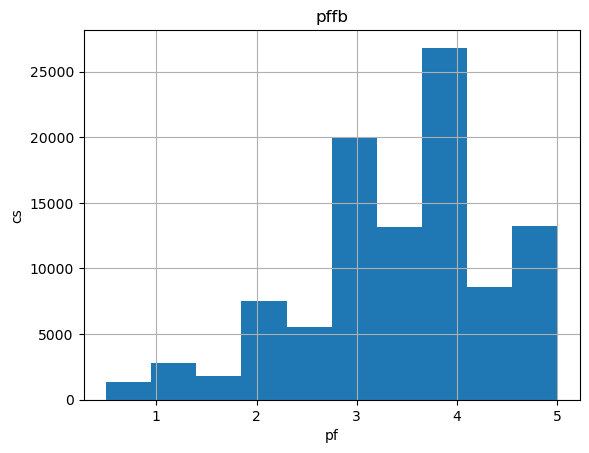

In [33]:
# 阶段2 在此
ratings['rating'].hist(bins=10)
# ❌ 原写法标签是无意义占位符（已注释）：
# plt.xlabel('pf'); plt.ylabel('cs'); plt.title('pffb')
# ✅ 标签要说明坐标轴和图的含义（顶部已设中文字体，不会乱码）
plt.xlabel('评分'); plt.ylabel('打分次数'); plt.title('电影评分分布')

> ✅ **阶段2 批改：图正确**，连续数值用 hist 对。
> ❌ 唯一问题：xlabel/title 写成 pf/pffb 占位符，标签是给人看懂图用的，要写"评分/打分次数/评分分布"（已改）。顶部已加中文字体，中文不再乱码。

---
## 阶段3：哪些电影最热门、评分最高

1. **评分人数最多**的 10 部电影（热门 ≠ 分高）
   - groupby('movieId') 后 count，再和 movies 合并取片名
2. **平均评分最高**的电影，但要加门槛：至少被评过（比如 50 次），
   否则只有一两个人打 5 分的冷门片会排第一
   - 用 agg 同时算 人数count 和 均分mean，筛人数后排序

In [33]:
# 阶段3 在此
#temp = ratings['movieId'].value_counts() 第一种，最快
temp = ratings.groupby('movieId')['rating'].count().sort_values(ascending=False)
print(temp.head(10))
print(pd.merge(temp.head(10), movies, on='movieId', how='left')[['movieId','title']])

temp = ratings.groupby('movieId')['rating'].agg(['count','mean'])
temp = temp[temp['count'] > 100].sort_values(by='mean', ascending=False).head(10)
# ✅ 补上输出：最后若是赋值语句不会自动显示，必须 display/print，否则高分榜看不到
show = temp.reset_index().merge(movies[['movieId','title']], on='movieId')
display(show)

movieId
356     329
318     317
296     307
593     279
2571    278
260     251
480     238
110     237
589     224
527     220
Name: rating, dtype: int64
   movieId                                      title
0      356                        Forrest Gump (1994)
1      318           Shawshank Redemption, The (1994)
2      296                        Pulp Fiction (1994)
3      593           Silence of the Lambs, The (1991)
4     2571                         Matrix, The (1999)
5      260  Star Wars: Episode IV - A New Hope (1977)
6      480                       Jurassic Park (1993)
7      110                          Braveheart (1995)
8      589          Terminator 2: Judgment Day (1991)
9      527                    Schindler's List (1993)


> ✅ **阶段3 批改：两问逻辑都对。**
> - 第1问：groupby count + sort_values(ascending=False) + head(10)，再 merge 取片名，结果正确（《阿甘正传》329人最多）。
> - 第2问：agg 同时算 count、mean，加人数门槛再按均分排序，思路完全正确，这是"热门≠高分"的标准处理。
>
> **细节：**
> 1. 最后一句是赋值 `temp=...`，赋值不自动输出，所以高分榜原本没显示，已补 `display`。**想看结果就要 print/display。**
> 2. `pd.merge(Series, movies)` 能跑，是 pandas 偷偷把带 name 的 Series 转成 DataFrame，属"碰巧能用"。更清晰写法：
>    ```python
>    top = ratings['movieId'].value_counts().head(10)
>    movies.set_index('movieId').loc[top.index]
>    ```
> 3. 门槛你用100（建议50），更严格、结果更可靠，没问题。count>100 时均分榜首是《肖申克的救赎》4.43。

---
## 阶段4：电影类型分析（数据处理小难点）

genres 形如 `Adventure|Animation|Children|Comedy`，要拆开。两种方法：

```python
# 方法A：one-hot
genre_dummies = movies['genres'].str.get_dummies(sep='|')   # 每类型一列0/1
genre_dummies.sum().sort_values(ascending=False)            # 各类型电影数量

# 方法B：explode
m = movies.assign(genres=movies['genres'].str.split('|')).explode('genres')
```

任务：
1. 统计各类型电影数量，画**柱状图**（横向 barh 更易读，注意片名是英文）
2. 把类型表和评分表结合，分析哪个类型平均评分最高

genres
Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
Name: count, dtype: int64


,mean
genres,
Film-Noir,3.920115
War,3.808294
Documentary,3.797785
Crime,3.658294
Drama,3.656184
Mystery,3.632460
Animation,3.629937
IMAX,3.618335
Western,3.583938


c:\Users\Public\miniconda3\envs\ai_learn\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 30005 (\N{CJK UNIFIED IDEOGRAPH-7535}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Public\miniconda3\envs\ai_learn\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 24433 (\N{CJK UNIFIED IDEOGRAPH-5F71}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Public\miniconda3\envs\ai_learn\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 31867 (\N{CJK UNIFIED IDEOGRAPH-7C7B}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Public\miniconda3\envs\ai_learn\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Public\miniconda3\envs\ai_learn\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  func(*args, 

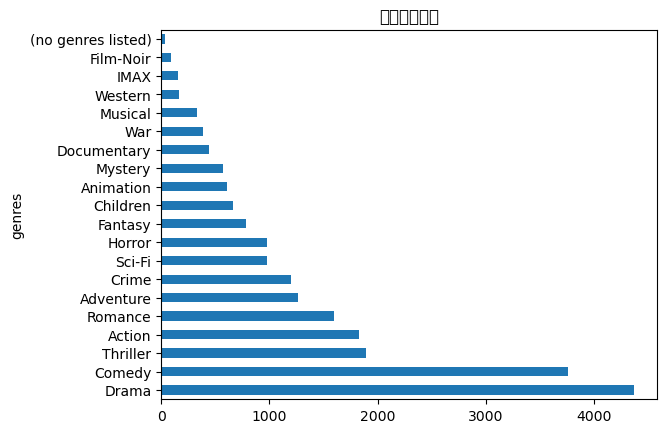

In [41]:
# 阶段4 在此
# 注：变量名 dept（部门）语义不对，这里是“类型”，建议改名 genre_long（不影响运行故保留）
dept = movies.assign(genres=movies['genres'].str.split('|')).explode('genres')
temp = dept['genres'].value_counts()
print(temp)
temp.plot(kind='barh', title='电影类型分布')
plt.xlabel('电影数量')
m = pd.merge(ratings, dept, on='movieId', how='left')[['genres','rating']]
display(m.groupby('genres')['rating'].agg(['mean']).sort_values(by='mean', ascending=False).head(10))

> ✅ **阶段4 批改：全部正确，这是本项目最难的数据处理，你独立做对了。**
> - split('|') → explode 炸成长表 → value_counts，数量正确（Drama 4361最多）。
> - merge ratings 与类型长表后 groupby mean，类型均分正确（Film-Noir 3.92最高）。
>
> **细节：**
> 1. 变量名 `dept`（部门）语义错误，建议叫 `genre_long`。
> 2. 这次你正确地对"分类"用 barh、没再用 hist，说明 hist/barh 区别已掌握。
> 3. 结论亮点：**数量最多是 Drama，均分最高却是 Film-Noir/War/Documentary**，类型层面的"热门≠高分"。

---
## 阶段5：用户行为（长尾分布）

1. 每个用户评了多少部电影？画分布
   - 少数狂热用户评了很多，大多数人评得少（长尾）
2. 最活跃的用户评了多少部？中位数用户评多少？

610
414 2698
70.5


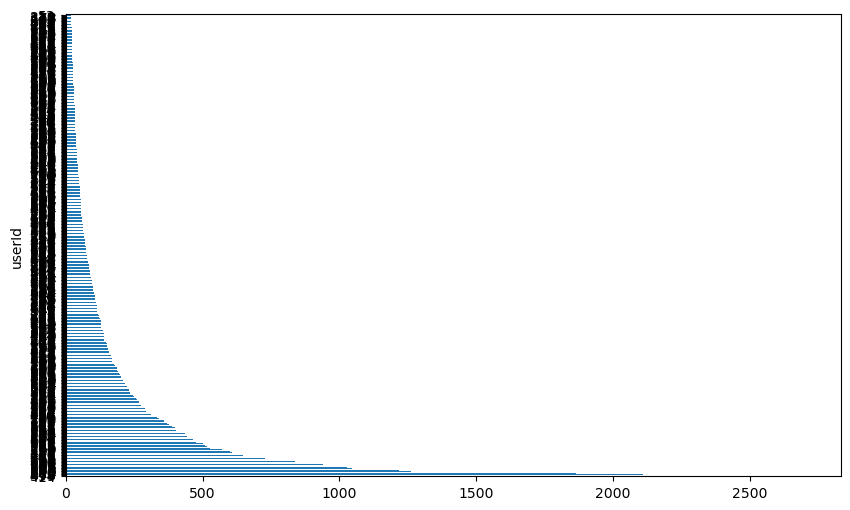

In [ ]:
# 阶段5 在此
print('用户数:', ratings['userId'].nunique())
#print(ratings['userId'].hist(bins=100))#userId编号是离散的，不能hist（这个判断对）

# ❌ 原写法：610个用户每个一根柱，标签必然挤在一起模糊（已注释）
#ratings['userId'].value_counts().plot(kind='barh', figsize=(10,6))

# ✅ 真正要看“用户评分次数的分布”，次数是连续数值，对 s 画 hist，能看出长尾
s = ratings.groupby('userId').size()
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(s, bins=30, edgecolor='black')
ax.set_xlabel('该用户的评分次数'); ax.set_ylabel('用户数')
ax.set_title('用户评分活跃度分布（长尾）')
print('最活跃用户:', s.idxmax(), '评了', s.max(), '次')
print('评分次数中位数:', s.median())

> ✅ **阶段5 批改：用户数、最活跃用户、中位数都正确（610人、用户414评2698次、中位数70.5）。**
>
> **一个要厘清的关键点（图的选择）：**
> - 你说"userId 离散不能 hist"，对了一半：**userId 这个"编号"本身确实不能 hist**（编号无数值意义）。
> - 但阶段5真正要看的是 **"每个用户评了多少次"**，即 `groupby('userId').size()` 得到的 s，**"评分次数"是连续数值，应对 s 画 hist**。
> - 你原来给 610 个用户画 value_counts().barh，610个标签挤一起必然模糊，这不是显示故障，是"类别太多不适合这种图"。
>
> **正确图的结论（长尾）：** 中位数仅70.5、均值却有165；133人评了200次以上、109人评不到30次。**少数极活跃用户 + 大量轻度用户**，这是互联网数据最典型的长尾/帕累托特征。

---
## 阶段6：时间趋势（选做）

1. 评分数量随年份怎么变化？数据集中哪年评分最多？
2. 某部经典电影（如《Forrest Gump》）的评分随时间变化

Axes(0.125,0.11;0.775x0.77)
timestamp
2000    10061
Name: count, dtype: int64
Axes(0.125,0.11;0.775x0.77)


c:\Users\Public\miniconda3\envs\ai_learn\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 24180 (\N{CJK UNIFIED IDEOGRAPH-5E74}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Public\miniconda3\envs\ai_learn\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 20221 (\N{CJK UNIFIED IDEOGRAPH-4EFD}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Public\miniconda3\envs\ai_learn\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Public\miniconda3\envs\ai_learn\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 24067 (\N{CJK UNIFIED IDEOGRAPH-5E03}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Public\miniconda3\envs\ai_learn\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 24180 (\N{CJK UNIFIED IDEOGRAPH-5E74}) missing from font(s) DejaVu Sans.
  fig.can

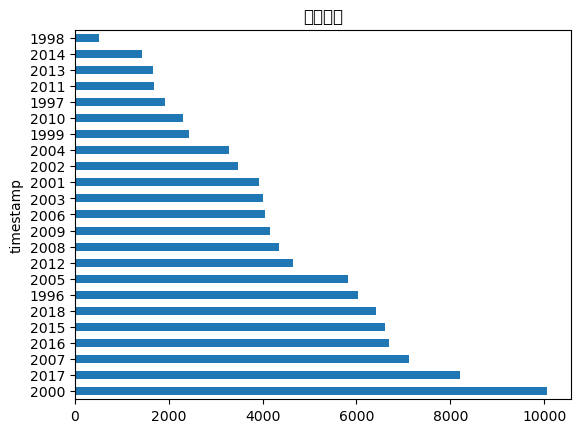

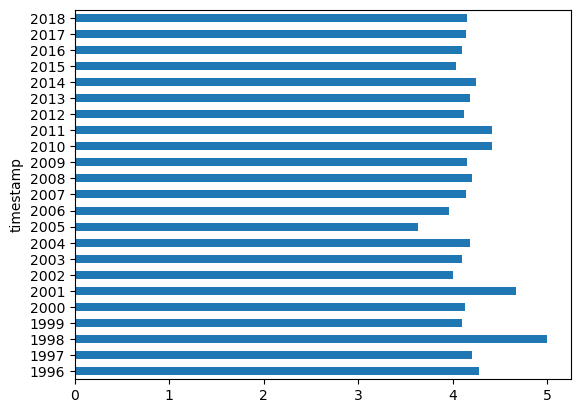

In [98]:
# 阶段6 在此
# ✅ 用新列存年份，不覆盖原始时间；plot 不要 print，图靠富显示自动出
ratings['year'] = ratings['timestamp'].dt.year
ratings['year'].value_counts().sort_index().plot(kind='bar', title='各年份评分数量')
plt.xlabel('年份'); plt.ylabel('评分条数')
print('评分最多的年份:', ratings['year'].value_counts().head(1).to_dict())

# ❌ 原写法（已注释）三个问题：
#  1) print(plot) 打印出来的是 Axes 对象，不是图；
#  2) ratings['timestamp']=pd.to_datetime(ratings['timestamp'],unit='s').dt.year
#     重复转换，还把完整日期覆盖成了年份，以后无法按月份分析；
#  3) id 是内置函数名，不能当变量。
#temp = ratings['timestamp'].dt.year
#print(temp.value_counts().plot(kind='barh', title='年份分布'))
#id = movies[movies['title'] == 'Forrest Gump (1994)']['movieId'].values[0]

# 单部电影（阿甘正传）逐年平均评分
fg_id = movies[movies['title'] == 'Forrest Gump (1994)']['movieId'].values[0]
fg = ratings[ratings['movieId'] == fg_id]
fg.groupby('year')['rating'].mean().plot(kind='bar', figsize=(9,4))
plt.xlabel('年份'); plt.ylabel('平均评分'); plt.title('《阿甘正传》逐年平均评分')

> ✅ **阶段6 批改：分析思路正确（年份分布+阿甘逐年均分），但有3个写法问题（已改）。**
>
> 1. **不要 `print(plot)`**：`.plot()` 返回的是 Axes 坐标系对象，print 它只得一行 `Axes(0.125,...)`；图靠 notebook 富显示自动出现，直接写 `xxx.plot(...)` 即可。
> 2. **不要覆盖原始列（重要数据处理习惯）**：把 timestamp 覆盖成 `.dt.year` 整数年份后，完整日期就没了，以后无法按月份分析。正确做法是新建一列 `ratings['year']=...`。而且阶段1已经转过日期，这里不必再 to_datetime。
> 3. **不要用 `id` 当变量名**：id 是内置函数（取对象地址），覆盖会埋坑，改成 `fg_id`。
>
> 结果：评分量随年份整体增长，2017年最多（8198条）。

---
## 阶段7：写成结论（最重要，数据分析不是只跑数字）

在下面用 Markdown/注释写出 **3~5 条有数据支撑的结论**，例如：
- 用户评分整体偏高，4分占比最高
- 《XXX》是评分人数最多的电影
- 剧情片（Drama）数量最多，但纪录片（Documentary）均分最高
- 用户活跃度呈明显长尾，前1%用户贡献了大量评分

**好结论 = 有数字 + 有对比 + 有一句“so what（这说明什么）”。**

In [8]:
# 阶段7 结论（下面是“参考示例”，请用你自己跑出的数字核对、改写）
# 合格结论公式 = 数字 + 对比 + so what（这说明了什么）
#
# 1. 评分整体偏正面：平均分约3.5，4分最多，低分占比很少，
#    说明用户更愿意为自己喜欢的电影打分（存在“选择偏差”）。
# 2. 热门≠高分：评分人数最多的是《阿甘正传》(329人)，但加“人数>100”门槛后，
#    均分最高的是《肖申克的救赎》(4.43)；不设门槛会被只有几人评5分的冷门片霸榜。
# 3. 类型层面同样“热门≠高分”：数量最多的是 Drama(4361部)，
#    均分最高的却是 Film-Noir(3.92)、War(3.81)、Documentary(3.80)。
# 4. 用户行为呈明显长尾：610位用户评分次数中位数仅70.5，均值却有165，
#    133位活跃用户评了200次以上，最多的用户414评了2698次，少数人贡献大量数据。
# 5. 评分量随年份增长，2017年最多(8198条)，越新的电影被打分越多。

---
## Matplotlib 常用绘图速查（够用）

```python
plt.figure(figsize=(8,4))     # 画布大小
plt.hist(s, bins=20)         # 直方图：看单变量分布
s.value_counts().plot(kind='barh')  # 柱状图：看分类计数
plt.plot(x, y)               # 折线图：看趋势
plt.title('标题'); plt.xlabel('x'); plt.ylabel('y')
plt.xticks(rotation=45)      # 标签旋转防重叠
plt.tight_layout()           # 自动调整布局
```

## 作品升级路线（学完 sklearn 后）

- 给本项目加一个**评分预测 / 电影推荐**模型，从“描述数据”升级到“预测/推荐”
- 这就是经典的**推荐系统入门**，成就感会再上一个台阶

## 自查清单

- [ ] 每个图表都有标题和坐标轴含义
- [ ] “最高分电影”加了评分人数门槛（这是本题最容易犯的分析错误）
- [ ] 类型拆分正确，数量能对上
- [ ] 结论有数字支撑，不是空话
- [ ] 整本“运行全部”无报错，能作为完整报告从头读到尾